In [1]:
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.impute import SimpleImputer
from sklearn.svm import SVC
from sklearn.model_selection import *
from sklearn.preprocessing import *
from sklearn.compose import *
from sklearn.metrics import *
import numpy as np
from plotnine import *
from sklearn.exceptions import ConvergenceWarning
import warnings

In [3]:
cah_train = "C:/Users/Ulises Caro Flores/OneDrive/Documents/MSBA Cal Poly/GSB 544 Computing and Machine Learning for Analysis/Finals/Kaggle Classification/CAH-201803-train.csv"
cah_test = "C:/Users/Ulises Caro Flores/OneDrive/Documents/MSBA Cal Poly/GSB 544 Computing and Machine Learning for Analysis/Finals/Kaggle Classification/CAH-201803-test.csv"

train = pd.read_csv(cah_train)
test = pd.read_csv(cah_test)

In [4]:
print(train.dtypes)
print(train.describe())
print(train.nunique)

id_num                    int64
Q1                       object
Q2                        int64
political_affiliation    object
Q4                       object
Q5                       object
Q6                       object
Q7                       object
Q8                       object
Q9                       object
Q10                      object
Q11                      object
Q12                      object
Q13                      object
Q14                      object
Q15                       int64
Q16                       int64
Q17                       int64
Q18                      object
dtype: object
           id_num          Q2         Q15         Q16         Q17
count  169.000000  169.000000  169.000000  169.000000  169.000000
mean   166.786982   47.508876    4.284024    2.970414    3.497041
std     97.770210   16.057233    1.277942    1.712788    1.484540
min      1.000000   18.000000    1.000000    1.000000    1.000000
25%     82.000000   35.000000    4.000000    1.0

In [5]:
train.isnull().sum()

id_num                   0
Q1                       0
Q2                       0
political_affiliation    0
Q4                       0
Q5                       0
Q6                       0
Q7                       0
Q8                       0
Q9                       0
Q10                      0
Q11                      0
Q12                      0
Q13                      0
Q14                      0
Q15                      0
Q16                      0
Q17                      0
Q18                      0
dtype: int64

In [6]:
train.nunique()

id_num                   169
Q1                         2
Q2                        56
political_affiliation      3
Q4                         3
Q5                         4
Q6                         4
Q7                         2
Q8                         2
Q9                         2
Q10                        3
Q11                        2
Q12                        2
Q13                        2
Q14                        3
Q15                        4
Q16                        4
Q17                        4
Q18                        2
dtype: int64

In [7]:
train["political_affiliation"].value_counts()

political_affiliation
Democrat       59
Independent    56
Republican     54
Name: count, dtype: int64

In [8]:
print(train.shape[0])
print(test.shape[0])

169
166


In [17]:
X = train.drop(columns=['political_affiliation', 'id_num'])
y = train['political_affiliation']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_test = test.drop(columns=['id_num'])

CV = StratifiedKFold(n_splits=10, shuffle=True, random_state=321)

In [10]:
num_var = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_var = X.select_dtypes(include=["object", "category"]).columns.tolist()

num_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

ct = ColumnTransformer(
    transformers=[
        ("num", num_pipe, num_var),
        ("cat", cat_pipe, cat_var),
    ]
)

score = "accuracy"

**Will comparing the models based on the best RMSE and hypertuning for: Logistic, KNN, DT, LDA, QDA, SVC, SVM (SVC with a kernel set to Poly)**

In [12]:
#Logistic Classification
log_pipe = Pipeline([
    ("preprocess", ct),
    ("log", LogisticRegression(max_iter=10000))
])

log_pipe.fit(X, y_encoded)

para_log = {
    "log__C": [0.01, 0.1, 1, 10],
    "log__penalty": ["l2"],
    "log__solver": ["lbfgs"]
}

log_search = GridSearchCV(log_pipe, para_log, cv=CV, scoring=score)
log_fit = log_search.fit(X, y_encoded)

In [13]:
log_fit.best_estimator_.named_steps["log"]

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,10000
,multi_class,'deprecated'


In [14]:
log_best = log_fit.best_estimator_
log_cv = cross_val_score(log_best, X, y_encoded, cv=CV, scoring=score)
log_est = log_cv.mean()
print(f"Estimated Accuracy Logistic Regression: {log_est:.4f}")

Estimated Accuracy Logistic Regression: 0.6162


Classification Report - Logistic Regression
              precision    recall  f1-score   support

    Democrat       0.58      0.64      0.61        59
 Independent       0.52      0.50      0.51        56
  Republican       0.76      0.70      0.73        54

    accuracy                           0.62       169
   macro avg       0.62      0.62      0.62       169
weighted avg       0.62      0.62      0.62       169



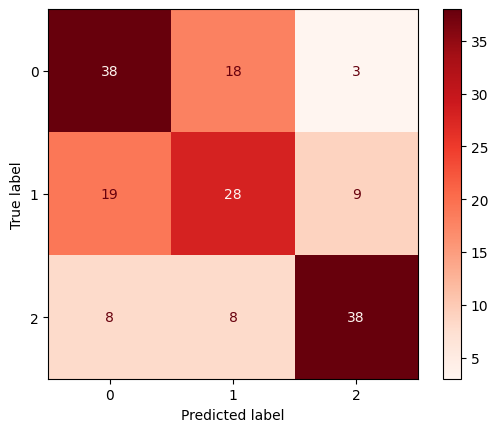

In [18]:
y_pred_log = cross_val_predict(log_best, X, y_encoded, cv=CV, method="predict")
ConfusionMatrixDisplay.from_predictions(y_encoded, y_pred_log, cmap="Reds")
print("Classification Report - Logistic Regression")
print(classification_report(y_encoded, y_pred_log, target_names=le.classes_))

In [19]:
#KNN Classification
knn_pipe = Pipeline([
    ("preprocess", ct),
    ("knn", KNeighborsClassifier())
])

knn_pipe.fit(X, y_encoded)

para_knn = {
    "knn__n_neighbors": [3, 5, 7, 9],
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"],
    "knn__p": [1, 2]
}

knn_search = GridSearchCV(knn_pipe, para_knn, cv=CV, scoring=score)
knn_fit = knn_search.fit(X, y_encoded)

In [20]:
knn_fit.best_estimator_.named_steps["knn"]

,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,1
,metric,'manhattan'
,metric_params,None
,n_jobs,None


In [21]:
knn_best = knn_fit.best_estimator_
knn_cv = cross_val_score(knn_best, X, y_encoded, cv=CV, scoring=score)
knn_est = knn_cv.mean()
print(f"Estimated Accuracy KNN: {knn_est:.4f}")

Estimated Accuracy KNN: 0.5739


Classification Report - KNN
              precision    recall  f1-score   support

    Democrat       0.54      0.63      0.58        59
 Independent       0.51      0.52      0.51        56
  Republican       0.72      0.57      0.64        54

    accuracy                           0.57       169
   macro avg       0.59      0.57      0.58       169
weighted avg       0.59      0.57      0.58       169



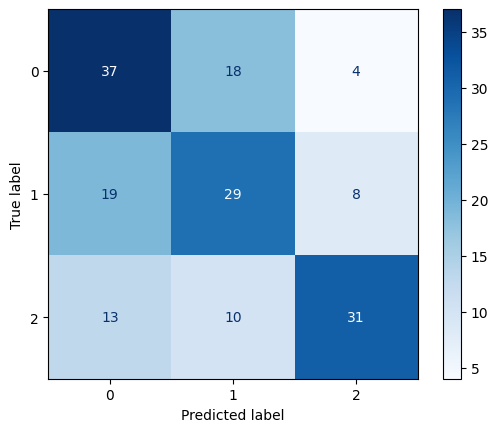

In [56]:
y_pred_knn = cross_val_predict(knn_best, X, y_encoded, cv=CV, method="predict")
ConfusionMatrixDisplay.from_predictions(y_encoded, y_pred_knn, cmap="Blues")
print("Classification Report - KNN")
print(classification_report(y_encoded, y_pred_knn, target_names=le.classes_))

In [22]:
#Decision Tree Classification
dt_pipe = Pipeline([
    ("preprocess", ct),
    ("dt", DecisionTreeClassifier(random_state=0))
])

dt_pipe.fit(X, y_encoded)

para_dt = {
    "dt__max_depth": [3, 5, 8, 12],
    "dt__min_samples_split": [2, 5, 8],
    "dt__min_samples_leaf": [1, 2, 4],
    "dt__max_features": ["sqrt", "log2"],
    "dt__ccp_alpha": [0.0]
}

dt_search = GridSearchCV(dt_pipe, para_dt, cv=CV, scoring=score)
dt_fit = dt_search.fit(X, y_encoded)

In [23]:
dt_fit.best_estimator_.named_steps["dt"]

,criterion,'gini'
,splitter,'best'
,max_depth,5
,min_samples_split,8
,min_samples_leaf,2
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,random_state,0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [24]:
dt_best = dt_fit.best_estimator_
dt_cv = cross_val_score(dt_best, X, y_encoded, cv=CV, scoring=score)
dt_est = dt_cv.mean()
print(f"Estimated Accuracy Decision Tree: {dt_est:.4f}")

Estimated Accuracy Decision Tree: 0.5434


Classification Report - Decision Tree
              precision    recall  f1-score   support

    Democrat       0.54      0.61      0.57        59
 Independent       0.49      0.52      0.50        56
  Republican       0.63      0.50      0.56        54

    accuracy                           0.54       169
   macro avg       0.55      0.54      0.54       169
weighted avg       0.55      0.54      0.54       169



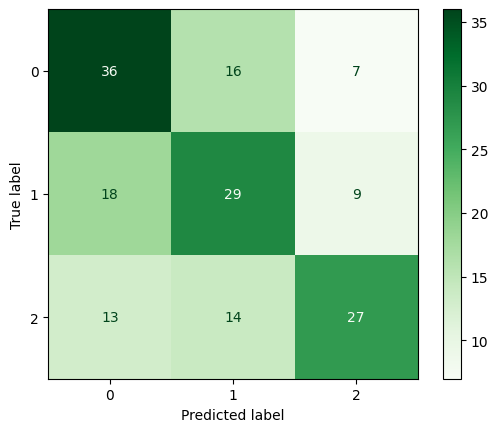

In [25]:
y_pred_dt = cross_val_predict(dt_best, X, y_encoded, cv=CV, method="predict")
ConfusionMatrixDisplay.from_predictions(y_encoded, y_pred_dt, cmap="Greens")
print("Classification Report - Decision Tree")
print(classification_report(y_encoded, y_pred_dt, target_names=le.classes_))

In [26]:
#Linear Discriminant Analysis
lda_pipe = Pipeline([
    ("preprocess", ct),
    ("lda", LinearDiscriminantAnalysis())
])

lda_pipe.fit(X, y_encoded)

para_lda = [
    {
        "lda__solver": ["svd"],
        "lda__shrinkage": [None]
    },
    {
        "lda__solver": ["lsqr"],
        "lda__shrinkage": [None, "auto", 0.01, 0.1, 0.5, 0.9, 1]
    }
]

lda_search = GridSearchCV(lda_pipe, para_lda, cv=CV, scoring=score)
lda_fit = lda_search.fit(X, y_encoded)

In [27]:
lda_fit.best_estimator_.named_steps["lda"]

,solver,'lsqr'
,shrinkage,0.5
,priors,None
,n_components,None
,store_covariance,False
,tol,0.0001
,covariance_estimator,None


In [28]:
lda_best = lda_fit.best_estimator_
lda_cv = cross_val_score(lda_best, X, y_encoded, cv=CV, scoring=score)
lda_est = lda_cv.mean()
print(f"Estimated Accuracy LDA: {lda_est:.4f}")

Estimated Accuracy LDA: 0.6037


Classification Report - LDA
              precision    recall  f1-score   support

    Democrat       0.57      0.63      0.60        59
 Independent       0.52      0.46      0.49        56
  Republican       0.72      0.72      0.72        54

    accuracy                           0.60       169
   macro avg       0.60      0.60      0.60       169
weighted avg       0.60      0.60      0.60       169



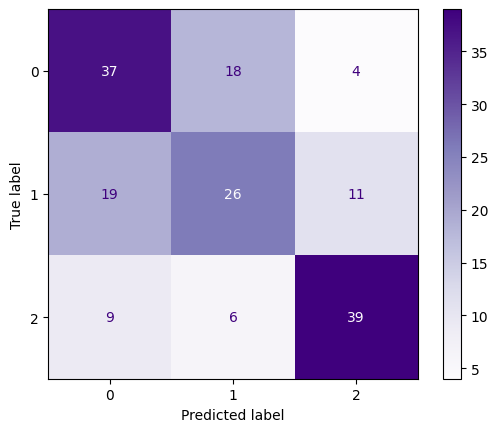

In [ ]:
y_pred_lda = cross_val_predict(lda_best, X, y_encoded, cv=CV, method="predict")
ConfusionMatrixDisplay.from_predictions(y_encoded, y_pred_lda, cmap="Purples")
print("Classification Report - LDA")
print(classification_report(y_encoded, y_pred_lda, target_names=le.classes_))

In [30]:
#Quadratic Discriminant Analysis
qda_pipe = Pipeline([
    ("preprocess", ct),
    ("qda", QuadraticDiscriminantAnalysis())
])

qda_pipe.fit(X, y_encoded)

warnings.filterwarnings(
    "ignore",
    message=".*covariance matrix of class.*"
)
para_qda = {
    "qda__reg_param": [0.0, 0.001, 0.01, 0.1, 0.3, 0.5, 0.9]
}

qda_search = GridSearchCV(qda_pipe, para_qda, cv=CV, scoring=score)
qda_fit = qda_search.fit(X, y_encoded)

C:\Users\Ulises Caro Flores\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 0 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
C:\Users\Ulises Caro Flores\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 1 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.
C:\Users\Ulises Caro Flores\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\discriminant_analysis.py:1024: LinAlgWarning: The covariance matrix of class 2 is not full rank. Increasing the value of parameter `reg_param` might help reducing the collinearity.


In [31]:
qda_fit.best_estimator_.named_steps["qda"]

,priors,None
,reg_param,0.5
,store_covariance,False
,tol,0.0001


In [32]:
qda_best = qda_fit.best_estimator_
qda_cv = cross_val_score(qda_best, X, y_encoded, cv=CV, scoring=score)
qda_est = qda_cv.mean()
print(f"Estimated Accuracy QDA: {qda_est:.4f}")

Estimated Accuracy QDA: 0.5680


Classification Report - QDA
              precision    recall  f1-score   support

    Democrat       0.54      0.59      0.56        59
 Independent       0.48      0.45      0.46        56
  Republican       0.69      0.67      0.68        54

    accuracy                           0.57       169
   macro avg       0.57      0.57      0.57       169
weighted avg       0.57      0.57      0.57       169



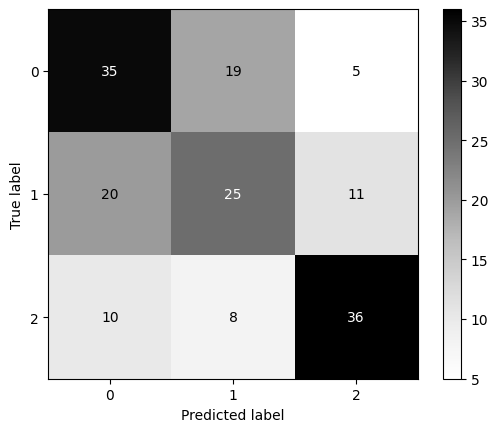

In [33]:
y_pred_qda = cross_val_predict(qda_best, X, y_encoded, cv=CV, method="predict")
ConfusionMatrixDisplay.from_predictions(y_encoded, y_pred_qda, cmap="Greys")
print("Classification Report - QDA")
print(classification_report(y_encoded, y_pred_qda, target_names=le.classes_))

In [34]:
#SVC (Base hypertune)
svc_pipe = Pipeline([
    ("preprocess", ct),
    ("svc", SVC())
])

svc_pipe.fit(X, y_encoded)

para_svc = {
    "svc__C": [0.1, 1, 10],
    "svc__kernel": ["linear", "rbf"],
    "svc__gamma": ["scale", "auto"]
}

svc_search = GridSearchCV(svc_pipe, para_svc, cv=CV, scoring=score)
svc_fit = svc_search.fit(X, y_encoded)

In [35]:
svc_fit.best_estimator_.named_steps["svc"]

,C,0.1
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [37]:
svc_best = svc_fit.best_estimator_
svc_cv = cross_val_score(svc_best, X, y_encoded, cv=CV, scoring=score)
svc_est = svc_cv.mean()
print(f"Estimated Accuracy SVC: {svc_est:.4f}")

Estimated Accuracy SVC: 0.6147


Classification Report - SVC
              precision    recall  f1-score   support

    Democrat       0.59      0.64      0.62        59
 Independent       0.54      0.55      0.55        56
  Republican       0.73      0.65      0.69        54

    accuracy                           0.62       169
   macro avg       0.62      0.62      0.62       169
weighted avg       0.62      0.62      0.62       169



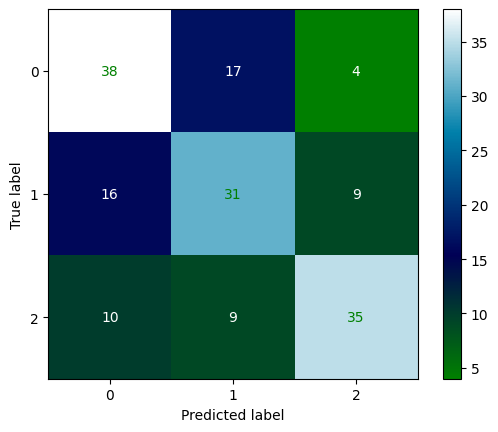

In [38]:
y_pred_svc = cross_val_predict(svc_best, X, y_encoded, cv=CV, method="predict")
ConfusionMatrixDisplay.from_predictions(y_encoded, y_pred_svc, cmap="ocean")
print("Classification Report - SVC")
print(classification_report(y_encoded, y_pred_svc, target_names=le.classes_))

In [39]:
#SVC (kernel = Poly)
svc_poly_pipe = Pipeline([
    ("preprocess", ct),
    ("svc", SVC(kernel="poly"))
])

svc_poly_pipe.fit(X, y_encoded)

para_svc_poly = {
    "svc__C": [0.1, 1, 10],
    "svc__degree": [2, 3, 4],
    "svc__gamma": ["scale", "auto"],
}

svc_poly_search = GridSearchCV(svc_poly_pipe, para_svc_poly, cv=CV, scoring=score)
svc_poly_fit = svc_poly_search.fit(X, y_encoded)

In [40]:
svc_poly_fit.best_estimator_.named_steps["svc"]

,C,1
,kernel,'poly'
,degree,4
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [41]:
svc_poly_best = svc_poly_fit.best_estimator_
svc_poly_cv = cross_val_score(svc_poly_best, X, y_encoded, cv=CV, scoring=score)
svc_poly_est = svc_poly_cv.mean()
print(f"Estimated Accuracy SVC Poly: {svc_poly_est:.4f}")

Estimated Accuracy SVC Poly: 0.6037


Classification Report - SVC Poly
              precision    recall  f1-score   support

    Democrat       0.57      0.63      0.60        59
 Independent       0.53      0.57      0.55        56
  Republican       0.75      0.61      0.67        54

    accuracy                           0.60       169
   macro avg       0.62      0.60      0.61       169
weighted avg       0.62      0.60      0.61       169



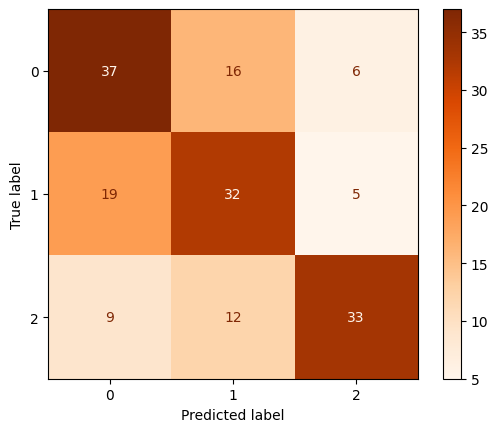

In [42]:
y_pred_svc_poly = cross_val_predict(svc_poly_best, X, y_encoded, cv=CV, method="predict")
ConfusionMatrixDisplay.from_predictions(y_encoded, y_pred_svc_poly, cmap="Oranges")
print("Classification Report - SVC Poly")
print(classification_report(y_encoded, y_pred_svc_poly, target_names=le.classes_))

In [43]:
#Comparison
acc_results_df = pd.DataFrame(
    {
        "Accuracy": [
            log_est,
            knn_est,
            dt_est,
            lda_est,
            qda_est,
            svc_est,
            svc_poly_est
        ]
    },
    index=[
        "Logistic Regression",
        "KNN",
        "Decision Tree",
        "LDA",
        "QDA",
        "SVC",
        "SVC Poly"
    ]
)

acc_results_df.sort_values(by="Accuracy", ascending=False).style.format("{:.4f}")

,Accuracy
Logistic Regression,0.6162
SVC,0.6147
SVC Poly,0.6037
LDA,0.6037
KNN,0.5739
QDA,0.5680
Decision Tree,0.5434


In [ ]:
#Selecting Logistic Regression as our best model and predicting over y_test
y_pred_enc = log_best.predict(X_test)
y_pred     = le.inverse_transform(y_pred_enc)

submission_classification = pd.DataFrame({
    "id_num": test["id_num"],
    "political_affiliation_predicted": y_pred
})

print(submission_classification.head())
print(submission_classification.shape[0])
print(test.shape[0])

   id_num political_affiliation_predicted
0       2                      Republican
1       3                        Democrat
2       4                        Democrat
3       6                      Republican
4      11                     Independent
166
166


In [45]:
submission_classification.to_csv("submission_classification.csv", index=False)
print("Submission file created!")

Submission file created!


In [47]:
y_pred_enc2 = svc_best.predict(X_test)
y_pred2     = le.inverse_transform(y_pred_enc2)

submission_classification_svc = pd.DataFrame({
    "id_num": test["id_num"],
    "political_affiliation_predicted": y_pred2
})

submission_classification_svc.to_csv("submission_classification_svc.csv", index=False)
print("Submission file created!")

Submission file created!


**Refining Logistic Regression to include l1 penalty and other solvers**

In [54]:
para_log_refined = [
    {
        "log__solver": ["lbfgs"],
        "log__penalty": ["l2"],
        "log__C": [0.005, 0.01, 0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10],
    },
    {
        "log__solver": ["saga"],
        "log__penalty": ["l1", "l2"],
        "log__C": [0.005, 0.01, 0.05, 0.1, 0.2, 0.5, 1, 2, 5, 10],
    },
]

log_search_refined = GridSearchCV(log_pipe, para_log_refined, cv=CV, scoring=score)
log_fit_refined    = log_search_refined.fit(X, y_encoded)

In [55]:
log_best_refined = log_fit.best_estimator_
log_cv2 = cross_val_score(log_best_refined, X, y_encoded, cv=CV, scoring=score)
log_est2 = log_cv2.mean()
print(f"Estimated Accuracy Logistic Regression: {log_est2:.4f}")

Estimated Accuracy Logistic Regression: 0.6162


**Refining to include l1 did nothing as we still got the same accuracy. Also, SVC (0.59036) performed worse on the data**